# Семинар 7. Вопросно-ответная система (IR-based Question Answering)

**Тема базы знаний:** «Правила пользования библиотекой университета».

В работе строится вопросно-ответная система информационно-поискового типа (Information Retrieval-based QA): вопрос пользователя сравнивается с вопросами из базы знаний, выбирается наиболее похожий, и выдаётся соответствующий ему ответ.

**Структура работы**

| Шаг | Содержание |
|---|---|
| Шаг 1 (базовая часть) | 1.1 база знаний · 1.2 предобработка · 1.3 Bag of Words · 1.4 поиск по мерам Жаккара, косинуса и Пирсона · 1.5 тестовые вопросы · 1.6 сравнительная таблица · 1.7 выводы |
| Шаг 2 | 2.1 TF-IDF · 2.2 расширение базы перефразировками и вариантами ответов · 2.3 диалоговый режим с порогом · 2.4 сравнение BoW и TF-IDF · 2.5 коэффициент Спирмена |
| Шаг 3 | 3.1 обучение системы · 3.2 автоматический выбор метрики · 3.3 пороги метрик · 3.4 автоматическая оценка качества · 3.5 сводная таблица и выбор лучшего подхода |

Схема работы системы соответствует принципу IR-based QA: подготовка документов → предобработка → построение поискового индекса (векторизация) → получение и обработка вопроса → поиск наиболее похожих документов по мере сходства → формирование ответа или вежливого отказа.

In [1]:
import re
import random
from collections import Counter
from functools import lru_cache

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import rankdata, pearsonr, spearmanr
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
import pymorphy3
from IPython.display import display, Markdown

pd.set_option("display.max_colwidth", 110)
pd.set_option("display.width", 220)
np.random.seed(42)

---
## Шаг 1. Базовая часть

### 1.1. База знаний «вопрос — ответ»

База знаний описывает правила пользования библиотекой вуза. Каждая запись (интент) содержит идентификатор, короткое название темы, список формулировок вопроса и список вариантов ответа. В базовой части используется **только первая формулировка вопроса и первый вариант ответа** каждой записи — это 22 пары «вопрос — ответ». Остальные формулировки и варианты ответов задействуются в шаге 2.2.

In [2]:
INTENTS = [
    {"id": "schedule", "title": "график работы",
     "questions": ["Каков график работы библиотеки?",
                   "Во сколько открывается библиотека?",
                   "До какого часа работает библиотека?",
                   "Работает ли библиотека в выходные дни?"],
     "answers": ["Библиотека работает с понедельника по пятницу с 9:00 до 20:00, в субботу — с 10:00 до 17:00, воскресенье — выходной.",
                 "Читальные залы открыты в будни с 9 до 20 часов и в субботу с 10 до 17 часов; в воскресенье библиотека закрыта."]},
    {"id": "registration", "title": "запись в библиотеку",
     "questions": ["Как записаться в библиотеку?",
                   "Что нужно для получения читательского билета?",
                   "Как стать читателем библиотеки?",
                   "Какие документы нужны для записи в библиотеку?"],
     "answers": ["Для записи нужно прийти на абонемент со студенческим билетом или пропуском сотрудника; читательский билет оформляется за 10 минут.",
                 "Читательский билет выдаётся на абонементе при предъявлении студенческого билета или пропуска сотрудника университета."]},
    {"id": "loan_period", "title": "срок выдачи книг",
     "questions": ["На какой срок выдаются книги?",
                   "Сколько дней можно держать книгу?",
                   "На сколько времени дают учебники?"],
     "answers": ["Учебная литература выдаётся на семестр, художественная и научная — на 30 дней.",
                 "Учебники выдаются до конца семестра, остальные книги — на один месяц."]},
    {"id": "max_books", "title": "лимит книг",
     "questions": ["Сколько книг можно взять одновременно?",
                   "Какое максимальное количество книг выдают на руки?",
                   "Есть ли ограничение на число взятых книг?"],
     "answers": ["Одновременно на руках у читателя может находиться не более 10 изданий.",
                 "Лимит выдачи — 10 изданий на одного читателя."]},
    {"id": "renewal", "title": "продление книг",
     "questions": ["Как продлить срок возврата книги?",
                   "Можно ли продлить книгу онлайн?",
                   "Что делать, если не успеваю вернуть книгу вовремя?"],
     "answers": ["Продлить книгу можно в личном кабинете на сайте библиотеки или на абонементе, если на неё нет очереди; продление допускается дважды по 14 дней.",
                 "Срок возврата продлевается в личном кабинете читателя или у библиотекаря, не более двух раз по 14 дней."]},
    {"id": "fine", "title": "штраф за просрочку",
     "questions": ["Какой штраф за просрочку возврата книги?",
                   "Что будет, если вернуть книгу поздно?",
                   "Берут ли пени за задержку книг?"],
     "answers": ["За каждый день просрочки начисляется пеня 10 рублей за издание, а выдача новых книг приостанавливается до погашения долга.",
                 "Просрочка стоит 10 рублей в день за каждое издание; пока долг не погашен, новые книги не выдаются."]},
    {"id": "lost_book", "title": "утеря книги",
     "questions": ["Что делать, если потерял книгу?",
                   "Как возместить утерянную книгу?",
                   "Я испортил книгу, что теперь делать?"],
     "answers": ["Утерянную или испорченную книгу нужно заменить таким же или равноценным изданием, согласованным с библиотекарем, либо возместить её стоимость.",
                 "При утере или порче издания читатель приносит такое же или равноценное издание либо оплачивает его стоимость."]},
    {"id": "reading_room", "title": "издания читального зала",
     "questions": ["Можно ли выносить книги из читального зала?",
                   "Разрешено ли брать домой книги из читального зала?",
                   "Выдаются ли на дом издания читального зала?"],
     "answers": ["Издания читального зала выдаются только для работы в зале, выносить их запрещено.",
                 "Книги и журналы читального зала на дом не выдаются."]},
    {"id": "e_resources", "title": "электронные ресурсы",
     "questions": ["Как получить доступ к электронным ресурсам библиотеки?",
                   "Как пользоваться электронной библиотекой из дома?",
                   "Есть ли удалённый доступ к базам данных?"],
     "answers": ["Доступ к электронным базам данных открыт из сети университета, а удалённо — через личный кабинет с корпоративной учётной записью.",
                 "Электронные ресурсы доступны в сети вуза и удалённо после входа под корпоративной учётной записью."]},
    {"id": "wifi", "title": "Wi-Fi",
     "questions": ["Есть ли в библиотеке Wi-Fi?",
                   "Как подключиться к интернету в библиотеке?",
                   "Какой пароль от беспроводной сети?"],
     "answers": ["В библиотеке работает беспроводная сеть университета; подключение выполняется по корпоративному логину и паролю.",
                 "Wi-Fi доступен во всех залах, для входа используется корпоративная учётная запись."]},
    {"id": "printing", "title": "печать и сканирование",
     "questions": ["Можно ли распечатать или отсканировать документы в библиотеке?",
                   "Где сделать ксерокопию?",
                   "Есть ли принтер в библиотеке?"],
     "answers": ["В зале самообслуживания есть принтеры и сканеры; печать стоит 5 рублей за страницу, сканирование бесплатное.",
                 "Печать и сканирование доступны в зале самообслуживания: печать — 5 рублей за лист, сканирование — бесплатно."]},
    {"id": "food", "title": "еда и напитки",
     "questions": ["Можно ли есть и пить в библиотеке?",
                   "Разрешено ли приносить еду в читальный зал?",
                   "Можно пить кофе в библиотеке?"],
     "answers": ["В читальных залах запрещено принимать пищу; разрешается только вода в закрытой бутылке.",
                 "Еда и напитки в залах запрещены, кроме воды в закрытой бутылке."]},
    {"id": "silence", "title": "тишина и телефоны",
     "questions": ["Можно ли разговаривать по телефону в библиотеке?",
                   "Какие правила тишины действуют в читальном зале?",
                   "Где можно поговорить вслух?"],
     "answers": ["В читальных залах нужно соблюдать тишину и переводить телефон в беззвучный режим; для разговоров есть холл и переговорные комнаты.",
                 "В залах соблюдается тишина, телефоны переводятся в беззвучный режим, разговаривать можно в холле."]},
    {"id": "group_rooms", "title": "комнаты для групповой работы",
     "questions": ["Как забронировать переговорную комнату для групповой работы?",
                   "Можно ли заказать аудиторию для командного проекта в библиотеке?",
                   "Где позаниматься группой?"],
     "answers": ["Комнату для групповой работы можно забронировать на сайте библиотеки на срок до 3 часов, группа — от 2 до 8 человек.",
                 "Переговорные комнаты бронируются на сайте библиотеки для групп от 2 до 8 человек, не более чем на 3 часа."]},
    {"id": "reservation", "title": "бронирование выданной книги",
     "questions": ["Как заказать книгу, которой нет в наличии?",
                   "Что делать, если все экземпляры книги выданы?",
                   "Можно ли поставить книгу в очередь?"],
     "answers": ["Если все экземпляры выданы, книгу можно забронировать в электронном каталоге; уведомление придёт на почту, когда издание вернут.",
                 "Выданную книгу можно поставить в очередь через электронный каталог, о её возвращении читатель получит письмо."]},
    {"id": "catalog", "title": "поиск в каталоге",
     "questions": ["Как найти нужную книгу в каталоге?",
                   "Где посмотреть, есть ли книга в библиотеке?",
                   "Как пользоваться электронным каталогом?"],
     "answers": ["Поиск выполняется в электронном каталоге на сайте библиотеки по автору, названию или ключевым словам; в карточке указаны шифр и наличие экземпляров.",
                 "Наличие книги проверяется в электронном каталоге: поиск идёт по автору, названию или ключевым словам."]},
    {"id": "interlibrary", "title": "межбиблиотечный абонемент",
     "questions": ["Можно ли получить книгу из другой библиотеки?",
                   "Работает ли межбиблиотечный абонемент?",
                   "Как заказать издание, которого нет в фонде?"],
     "answers": ["Издания, отсутствующие в фонде, заказываются через межбиблиотечный абонемент; срок доставки — от 7 до 14 дней.",
                 "Книги из других библиотек доставляются по межбиблиотечному абонементу за 7–14 дней."]},
    {"id": "clearance", "title": "обходной лист",
     "questions": ["Как получить обходной лист при отчислении или выпуске?",
                   "Что нужно сделать в библиотеке перед получением диплома?",
                   "Как закрыть читательский билет?"],
     "answers": ["Перед выпуском нужно вернуть все книги и погасить задолженности, после чего библиотекарь подписывает обходной лист.",
                 "Обходной лист подписывается на абонементе после возврата всех изданий и погашения долгов."]},
    {"id": "cloakroom", "title": "гардероб и камеры хранения",
     "questions": ["Можно ли проходить в читальный зал с верхней одеждой и сумками?",
                   "Где оставить вещи в библиотеке?",
                   "Есть ли камера хранения в библиотеке?"],
     "answers": ["Верхняя одежда сдаётся в гардероб, а крупные сумки и рюкзаки — в камеры хранения у входа.",
                 "Пальто оставляется в гардеробе, рюкзаки и большие сумки — в камерах хранения у входа в библиотеку."]},
    {"id": "theses", "title": "выпускные работы",
     "questions": ["Где можно найти выпускные квалификационные работы прошлых лет?",
                   "Хранит ли библиотека дипломные работы?",
                   "Как посмотреть магистерские диссертации?"],
     "answers": ["Выпускные работы прошлых лет доступны в электронном репозитории университета; полные тексты открыты студентам после авторизации.",
                 "Дипломные и магистерские работы хранятся в электронном репозитории вуза и доступны после входа под учётной записью."]},
    {"id": "bibliography", "title": "оформление списка литературы",
     "questions": ["Помогают ли в библиотеке оформить список литературы?",
                   "Где получить консультацию по оформлению библиографии?",
                   "Как правильно оформить ссылки по ГОСТу?"],
     "answers": ["Библиографы консультируют по оформлению списков литературы по ГОСТ ежедневно с 12:00 до 16:00 в справочно-библиографическом отделе.",
                 "Консультации по оформлению библиографии и ссылок по ГОСТ проводятся в справочно-библиографическом отделе с 12 до 16 часов."]},
    {"id": "guests", "title": "сторонние читатели",
     "questions": ["Могут ли посетители не из университета пользоваться библиотекой?",
                   "Пускают ли в библиотеку сторонних читателей?",
                   "Можно ли прийти в библиотеку выпускнику?"],
     "answers": ["Сторонние читатели и выпускники могут работать в читальных залах по разовому пропуску, оформляемому по паспорту, без выдачи книг на дом.",
                 "Гости и выпускники допускаются в читальные залы по разовому пропуску, книги на дом им не выдаются."]},
]

TITLE = {it["id"]: it["title"] for it in INTENTS}
ANSWER = {it["id"]: it["answers"][0] for it in INTENTS}

BASE_KB = pd.DataFrame([{"intent": it["id"], "Тема": it["title"],
                         "Вопрос": it["questions"][0], "Ответ": it["answers"][0]} for it in INTENTS])
print(f"Базовая база знаний: {len(BASE_KB)} пар «вопрос — ответ»")
display(BASE_KB[["Тема", "Вопрос", "Ответ"]])

Базовая база знаний: 22 пар «вопрос — ответ»


,Тема,Вопрос,Ответ
0,график работы,Каков график работы библиотеки?,"Библиотека работает с понедельника по пятницу с 9:00 до 20:00, в субботу — с 10:00 до 17:00, воскресенье —..."
1,запись в библиотеку,Как записаться в библиотеку?,Для записи нужно прийти на абонемент со студенческим билетом или пропуском сотрудника; читательский билет ...
2,срок выдачи книг,На какой срок выдаются книги?,"Учебная литература выдаётся на семестр, художественная и научная — на 30 дней."
3,лимит книг,Сколько книг можно взять одновременно?,Одновременно на руках у читателя может находиться не более 10 изданий.
4,продление книг,Как продлить срок возврата книги?,"Продлить книгу можно в личном кабинете на сайте библиотеки или на абонементе, если на неё нет очереди; про..."
5,штраф за просрочку,Какой штраф за просрочку возврата книги?,"За каждый день просрочки начисляется пеня 10 рублей за издание, а выдача новых книг приостанавливается до ..."
6,утеря книги,"Что делать, если потерял книгу?","Утерянную или испорченную книгу нужно заменить таким же или равноценным изданием, согласованным с библиоте..."
7,издания читального зала,Можно ли выносить книги из читального зала?,"Издания читального зала выдаются только для работы в зале, выносить их запрещено."
8,электронные ресурсы,Как получить доступ к электронным ресурсам библиотеки?,"Доступ к электронным базам данных открыт из сети университета, а удалённо — через личный кабинет с корпора..."
9,Wi-Fi,Есть ли в библиотеке Wi-Fi?,В библиотеке работает беспроводная сеть университета; подключение выполняется по корпоративному логину и п...


### 1.2. Предобработка текстов

Предобработка выполняется в следующем порядке:

1. **приведение к нижнему регистру** и замена «ё» на «е»;
2. **токенизация** регулярным выражением: токеном считается последовательность букв/цифр, допускается дефис внутри слова (`wi-fi`);
3. **лемматизация** морфологическим анализатором `pymorphy3` (выбрана вместо стемминга, так как для русского языка она точнее: «выдаются» → «выдаваться», «книги» → «книга», тогда как стеммер лишь обрезает окончания);
4. **удаление стоп-слов** — используется стандартный список русских стоп-слов (как в NLTK), дополненный словом «каков». Проверка выполняется и для исходной словоформы, и для леммы, чтобы, например, «какие» (лемма «какой») тоже отбрасывалось.

Знаки препинания при токенизации отбрасываются.

In [3]:
STOP_WORDS = set('''и в во не что он на я с со как а то все она так его но да ты к у же вы за бы по только ее мне было
вот от меня еще нет о из ему теперь когда даже ну вдруг ли если уже или ни быть был него до вас нибудь опять уж вам
ведь там потом себя ничего ей может они тут где есть надо ней для мы тебя их чем была сам чтоб без будто чего раз тоже
себе под будет ж тогда кто этот того потому этого какой совсем ним здесь этом один почти мой тем чтобы нее сейчас были
куда зачем всех никогда можно при наконец два об другой хоть после над больше тот через эти нас про всего них какая много
разве три эту моя впрочем хорошо свою этой перед иногда лучше чуть том нельзя такой им более всегда конечно всю между весь каков каковой'''.split())

MORPH = pymorphy3.MorphAnalyzer()
TOKEN_RE = re.compile(r"[a-zа-я0-9]+(?:-[a-zа-я0-9]+)*")

def normalize(text):
    return text.lower().replace("ё", "е")

def tokenize(text):
    return TOKEN_RE.findall(normalize(text))

@lru_cache(maxsize=None)
def lemma(word):
    return MORPH.parse(word)[0].normal_form.replace("ё", "е")

def preprocess(text, remove_stop=True):
    # Полный конвейер: регистр -> токены -> леммы -> удаление стоп-слов
    result = []
    for tok in tokenize(text):
        lem = lemma(tok)
        if remove_stop and (tok in STOP_WORDS or lem in STOP_WORDS):
            continue
        result.append(lem)
    return result

demo = BASE_KB["Вопрос"].head(6)
display(pd.DataFrame({
    "Исходный вопрос": demo,
    "Токены": [tokenize(q) for q in demo],
    "Леммы (без стоп-слов)": [preprocess(q) for q in demo],
}))

,Исходный вопрос,Токены,Леммы (без стоп-слов)
0,Каков график работы библиотеки?,"[каков, график, работы, библиотеки]","[график, работа, библиотека]"
1,Как записаться в библиотеку?,"[как, записаться, в, библиотеку]","[записаться, библиотека]"
2,На какой срок выдаются книги?,"[на, какой, срок, выдаются, книги]","[срок, выдаваться, книга]"
3,Сколько книг можно взять одновременно?,"[сколько, книг, можно, взять, одновременно]","[сколько, книга, взять, одновременно]"
4,Как продлить срок возврата книги?,"[как, продлить, срок, возврата, книги]","[продлить, срок, возврат, книга]"
5,Какой штраф за просрочку возврата книги?,"[какой, штраф, за, просрочку, возврата, книги]","[штраф, просрочка, возврат, книга]"


### 1.3. Векторизация методом Bag of Words

В модели «мешок слов» каждый текст представляется вектором длины $|V|$ (размер словаря, построенного по вопросам базы знаний); $j$-я координата равна числу вхождений $j$-й леммы в текст. Порядок слов не учитывается.

Векторизация выполняется классом `CountVectorizer` из scikit-learn, на вход которому подаются уже предобработанные списки лемм (собственный анализатор). Тот же класс-индекс в шаге 2 используется и для TF-IDF. Слова запроса, отсутствующие в словаре базы, в векторе запроса не отражаются (для меры Жаккара они учитываются, так как она считается по множествам токенов).

In [4]:
def identity(tokens):
    return tokens

class TextIndex:
    # Векторный поисковый индекс по набору текстов: 'bow' (CountVectorizer) или 'tfidf' (TfidfVectorizer)
    def __init__(self, texts, weighting="bow"):
        self.weighting = weighting
        self.docs = [preprocess(t) for t in texts]
        self.sets = [set(d) for d in self.docs]
        vec_cls = CountVectorizer if weighting == "bow" else TfidfVectorizer
        self.vectorizer = vec_cls(analyzer=identity)
        self.matrix = self.vectorizer.fit_transform(self.docs).toarray().astype(float)
        self.vocab = self.vectorizer.get_feature_names_out()

    def transform(self, tokens):
        return self.vectorizer.transform([tokens]).toarray()[0].astype(float)

bow_base = TextIndex(BASE_KB["Вопрос"], "bow")
print("Размер словаря базовой базы знаний:", len(bow_base.vocab))
bow_df = pd.DataFrame(bow_base.matrix[:5], columns=bow_base.vocab, index=BASE_KB["Вопрос"].head(5))
display(bow_df.loc[:, (bow_df != 0).any()].astype(int))

Размер словаря базовой базы знаний: 60


,библиотека,взять,возврат,выдаваться,график,записаться,книга,одновременно,продлить,работа,сколько,срок
Вопрос,,,,,,,,,,,,
Каков график работы библиотеки?,1,0,0,0,1,0,0,0,0,1,0,0
Как записаться в библиотеку?,1,0,0,0,0,1,0,0,0,0,0,0
На какой срок выдаются книги?,0,0,0,1,0,0,1,0,0,0,0,1
Сколько книг можно взять одновременно?,0,1,0,0,0,0,1,1,0,0,1,0
Как продлить срок возврата книги?,0,0,1,0,0,0,1,0,1,0,0,1


### 1.4. Поиск ответа по мерам сходства

Для вопроса пользователя вычисляется сходство с каждым вопросом базы знаний, выбирается наиболее похожий вопрос и выдаётся соответствующий ему ответ. Используются три меры.

**Коэффициент Жаккара** (по множествам лемм $A$ и $B$):
$$K_J = \frac{C}{A + B - C} = \frac{|A\cap B|}{|A\cup B|},$$
где $A$, $B$ — число уникальных токенов первого и второго текста, $C = |A\cap B|$ — число общих токенов. (На слайде в числителе указано $A$, однако по определению коэффициента и согласно диаграмме Венна в числителе стоит пересечение $C$, иначе мера не была бы симметричной и не равнялась бы 1 только для совпадающих множеств.) Мера бинарная: учитывается только наличие слова.

**Косинусное расстояние** $S = 1 - \cos(A, B) = 1 - \dfrac{A\cdot B}{\|A\|\,\|B\|}$. Для ранжирования удобнее использовать само косинусное сходство $\cos(A,B)$: минимальному расстоянию соответствует максимальное сходство, поэтому выбор ответа от этого не меняется.

**Коэффициент корреляции Пирсона** между векторами текстов:
$$r = \frac{\sum_i (x_i-\bar x)(y_i-\bar y)}{\sqrt{\sum_i (x_i-\bar x)^2 \cdot \sum_i (y_i-\bar y)^2}},$$
что эквивалентно косинусу между центрированными векторами. Если вектор запроса нулевой (все слова вне словаря), дисперсия равна нулю, и сходство принимается равным 0.

Для каждого интента итоговое сходство — максимум по его формулировкам вопроса (в базовой части формулировка одна).

In [5]:
def jaccard(a, b):
    a, b = set(a), set(b)
    c = len(a & b)
    denom = len(a) + len(b) - c
    return c / denom if denom else 0.0

def cosine_sim(x, y):
    nx, ny = np.linalg.norm(x), np.linalg.norm(y)
    return float(x @ y / (nx * ny)) if nx > 0 and ny > 0 else 0.0

def pearson_sim(x, y):
    return cosine_sim(x - x.mean(), y - y.mean())

def spearman_sim(x, y):
    # Корреляция Спирмена = корреляция Пирсона между рангами (используется в шаге 2.5)
    return pearson_sim(rankdata(x), rankdata(y))

VECTOR_METRICS = {"cosine": cosine_sim, "pearson": pearson_sim, "spearman": spearman_sim}
METRIC_NAMES = {"jaccard": "Жаккар", "cosine": "Косинус", "pearson": "Пирсон", "spearman": "Спирмен"}

# Проверка собственных реализаций по библиотечным функциям
x, y = bow_base.matrix[0], bow_base.matrix[2]
print("Пирсон: собственная =", round(pearson_sim(x, y), 6), "| scipy =", round(pearsonr(x, y).statistic, 6))
print("Спирмен: собственная =", round(spearman_sim(x, y), 6), "| scipy =", round(spearmanr(x, y).statistic, 6))

Пирсон: собственная = -0.052632 | scipy = -0.052632
Спирмен: собственная = -0.052632 | scipy = -0.052632


In [6]:
class Retriever:
    # Поиск ближайших вопросов базы знаний; intents[i] — интент i-го вопроса
    def __init__(self, questions, intents, weighting="bow"):
        self.intents = list(intents)
        self.index = TextIndex(list(questions), weighting)

    def scores(self, query, metric):
        tokens = preprocess(query)
        if metric == "jaccard":
            return np.array([jaccard(tokens, s) for s in self.index.sets])
        q = self.index.transform(tokens)
        f = VECTOR_METRICS[metric]
        return np.array([f(q, row) for row in self.index.matrix])

    def rank(self, query, metric):
        # Список (интент, сходство) по убыванию; сходство интента — максимум по его формулировкам
        best = {}
        for intent, s in zip(self.intents, self.scores(query, metric)):
            if intent not in best or s > best[intent]:
                best[intent] = s
        return sorted(best.items(), key=lambda kv: -kv[1])

base_bow = Retriever(BASE_KB["Вопрос"], BASE_KB["intent"], "bow")

def ask_basic(query, metric, retriever=base_bow):
    intent, score = retriever.rank(query, metric)[0]
    return intent, score, ANSWER[intent]

for q in ["Сколько книг дают на руки?", "Где можно распечатать реферат?"]:
    print("Вопрос:", q)
    for m in ["jaccard", "cosine", "pearson"]:
        intent, score, ans = ask_basic(q, m)
        print(f"  {METRIC_NAMES[m]:8s} сходство={score:.3f}  ->  {ans}")
    print()

Вопрос: Сколько книг дают на руки?
  Жаккар   сходство=0.333  ->  Одновременно на руках у читателя может находиться не более 10 изданий.
  Косинус  сходство=0.707  ->  Одновременно на руках у читателя может находиться не более 10 изданий.
  Пирсон   сходство=0.695  ->  Одновременно на руках у читателя может находиться не более 10 изданий.

Вопрос: Где можно распечатать реферат?
  Жаккар   сходство=0.200  ->  В зале самообслуживания есть принтеры и сканеры; печать стоит 5 рублей за страницу, сканирование бесплатное.
  Косинус  сходство=0.500  ->  В зале самообслуживания есть принтеры и сканеры; печать стоит 5 рублей за страницу, сканирование бесплатное.
  Пирсон   сходство=0.487  ->  В зале самообслуживания есть принтеры и сканеры; печать стоит 5 рублей за страницу, сканирование бесплатное.



### 1.5. Тестовые вопросы

Подготовлено 15 вопросов, ответы на которые есть в базе знаний (они **сформулированы иначе**, чем вопросы базы, чтобы проверка не сводилась к точному совпадению), и 7 вопросов, ответов на которые в базе нет. Среди последних есть «коварные» вопросы, лексически близкие к тематике библиотеки («Можно ли взять ноутбук в библиотеке?», «Как записаться в спортивную секцию?»).

Отдельно подготовлен **валидационный набор** (12 + 5 вопросов), который не используется при оценке качества, а служит только для подбора порогов в шаге 3.3. Это исключает подгонку порогов под тестовую выборку.

In [7]:
TEST_IN = [
    ("Во сколько закрывается библиотека в субботу?", "schedule"),
    ("Как оформить читательский билет первокурснику?", "registration"),
    ("Сколько дней можно не сдавать художественную книгу?", "loan_period"),
    ("Какой лимит на количество книг у одного читателя?", "max_books"),
    ("Можно ли продлить учебник через личный кабинет?", "renewal"),
    ("Сколько стоит каждый день задержки возврата книги?", "fine"),
    ("Я потерял библиотечную книгу, как быть?", "lost_book"),
    ("Можно взять домой журнал из читального зала?", "reading_room"),
    ("Как зайти в электронные базы данных не из университета?", "e_resources"),
    ("Есть ли беспроводной интернет в библиотеке?", "wifi"),
    ("Сколько стоит печать одной страницы?", "printing"),
    ("Можно ли перекусить в читальном зале?", "food"),
    ("Нужно ли выключать звук телефона в библиотеке?", "silence"),
    ("Как забронировать комнату для работы в команде?", "group_rooms"),
    ("Где почитать дипломы выпускников прошлых лет?", "theses"),
]
TEST_OUT = [
    "Как поступить в магистратуру?",
    "Где находится столовая?",
    "Какая стипендия у отличников?",
    "Как перевестись на другой факультет?",
    "Когда начинается зимняя сессия?",
    "Можно ли взять ноутбук в библиотеке?",
    "Как записаться в спортивную секцию?",
]
TEST = TEST_IN + [(q, None) for q in TEST_OUT]

DEV = [
    ("Работает ли библиотека по воскресеньям?", "schedule"),
    ("Какие документы нужны, чтобы стать читателем?", "registration"),
    ("Какая пеня за просроченную книгу?", "fine"),
    ("Что делать, если испортил учебник?", "lost_book"),
    ("Где можно отсканировать конспект?", "printing"),
    ("Можно ли пить чай в читальном зале?", "food"),
    ("Как найти книгу по автору?", "catalog"),
    ("Как заказать книгу из другого города?", "interlibrary"),
    ("Что нужно сдать в библиотеку перед выпуском?", "clearance"),
    ("Кто поможет оформить список литературы для курсовой?", "bibliography"),
    ("Может ли выпускник ходить в библиотеку?", "guests"),
    ("Куда сдать рюкзак перед входом в читальный зал?", "cloakroom"),
    ("Как получить справку об обучении?", None),
    ("Где проходят занятия по физкультуре?", None),
    ("Когда будет выпускной?", None),
    ("Какой номер телефона деканата?", None),
    ("Как оформить академический отпуск?", None),
]

print(f"Тест: {len(TEST_IN)} вопросов с ответом в базе, {len(TEST_OUT)} без ответа")
print(f"Валидация: {sum(t is not None for _, t in DEV)} с ответом, {sum(t is None for _, t in DEV)} без ответа")

Тест: 15 вопросов с ответом в базе, 7 без ответа
Валидация: 12 с ответом, 5 без ответа


### 1.6. Сравнительная таблица по мерам сходства

Для каждого тестового вопроса в столбцах метрик указаны: максимальное сходство, тема найденного ответа и отметка правильности (✓/✗). Столбец «Ответ системы» содержит ответ, выбранный **большинством голосов** трёх мер (если все три меры выбрали разные ответы — берётся ответ по косинусу). Для вопросов, ответа на которые нет в базе, правильным поведением считается отказ; в базовой части порога нет, поэтому система всегда выдаёт какой-нибудь ответ и такие вопросы помечаются ✗.

In [8]:
BASE_METRICS = ["jaccard", "cosine", "pearson"]

def comparison_table(retriever, metrics, test):
    rows = []
    for q, true in test:
        preds, cells = {}, {}
        for m in metrics:
            intent, score = retriever.rank(q, m)[0]
            preds[m] = intent
            cells[METRIC_NAMES[m]] = f"{score:.3f} · {TITLE[intent]} {'✓' if intent == true else '✗'}"
        top_vote, n_votes = Counter(preds.values()).most_common(1)[0]
        system = top_vote if n_votes >= 2 else preds["cosine"]
        rows.append({"Вопрос": q,
                     "Правильный ответ": ANSWER[true] if true else "— (ответа в базе нет)",
                     "Ответ системы": ANSWER[system], **cells})
    return pd.DataFrame(rows)

table_16 = comparison_table(base_bow, BASE_METRICS, TEST)
display(table_16)

,Вопрос,Правильный ответ,Ответ системы,Жаккар,Косинус,Пирсон
0,Во сколько закрывается библиотека в субботу?,"Библиотека работает с понедельника по пятницу с 9:00 до 20:00, в субботу — с 10:00 до 17:00, воскресенье —...",Для записи нужно прийти на абонемент со студенческим билетом или пропуском сотрудника; читательский билет ...,0.200 · запись в библиотеку ✗,0.500 · запись в библиотеку ✗,0.483 · запись в библиотеку ✗
1,Как оформить читательский билет первокурснику?,Для записи нужно прийти на абонемент со студенческим билетом или пропуском сотрудника; читательский билет ...,Библиографы консультируют по оформлению списков литературы по ГОСТ ежедневно с 12:00 до 16:00 в справочно-...,0.125 · оформление списка литературы ✗,0.447 · оформление списка литературы ✗,0.432 · оформление списка литературы ✗
2,Сколько дней можно не сдавать художественную книгу?,"Учебная литература выдаётся на семестр, художественная и научная — на 30 дней.",Одновременно на руках у читателя может находиться не более 10 изданий.,0.286 · лимит книг ✗,0.707 · лимит книг ✗,0.695 · лимит книг ✗
3,Какой лимит на количество книг у одного читателя?,Одновременно на руках у читателя может находиться не более 10 изданий.,"Учебная литература выдаётся на семестр, художественная и научная — на 30 дней.",0.167 · срок выдачи книг ✗,0.577 · срок выдачи книг ✗,0.567 · срок выдачи книг ✗
4,Можно ли продлить учебник через личный кабинет?,"Продлить книгу можно в личном кабинете на сайте библиотеки или на абонементе, если на неё нет очереди; про...","Продлить книгу можно в личном кабинете на сайте библиотеки или на абонементе, если на неё нет очереди; про...",0.143 · продление книг ✓,0.500 · продление книг ✓,0.487 · продление книг ✓
5,Сколько стоит каждый день задержки возврата книги?,"За каждый день просрочки начисляется пеня 10 рублей за издание, а выдача новых книг приостанавливается до ...",Одновременно на руках у читателя может находиться не более 10 изданий.,0.222 · лимит книг ✗,0.577 · лимит книг ✗,0.552 · продление книг ✗
6,"Я потерял библиотечную книгу, как быть?","Утерянную или испорченную книгу нужно заменить таким же или равноценным изданием, согласованным с библиоте...","Утерянную или испорченную книгу нужно заменить таким же или равноценным изданием, согласованным с библиоте...",0.500 · утеря книги ✓,0.816 · утеря книги ✓,0.809 · утеря книги ✓
7,Можно взять домой журнал из читального зала?,"Издания читального зала выдаются только для работы в зале, выносить их запрещено.","Издания читального зала выдаются только для работы в зале, выносить их запрещено.",0.286 · издания читального зала ✓,0.577 · издания читального зала ✓,0.552 · издания читального зала ✓
8,Как зайти в электронные базы данных не из университета?,"Доступ к электронным базам данных открыт из сети университета, а удалённо — через личный кабинет с корпора...","Доступ к электронным базам данных открыт из сети университета, а удалённо — через личный кабинет с корпора...",0.111 · электронные ресурсы ✓,0.316 · электронные ресурсы ✓,0.280 · электронные ресурсы ✓
9,Есть ли беспроводной интернет в библиотеке?,В библиотеке работает беспроводная сеть университета; подключение выполняется по корпоративному логину и п...,Для записи нужно прийти на абонемент со студенческим билетом или пропуском сотрудника; читательский билет ...,0.250 · запись в библиотеку ✗,0.707 · запись в библиотеку ✗,0.701 · запись в библиотеку ✗


In [9]:
def score_stats(retriever, metrics, test):
    # Сводная статистика: точность top-1 на вопросах из базы и уровни сходства
    rows = []
    for m in metrics:
        top_in, ok, top_out, margins = [], [], [], []
        for q, true in test:
            ranking = retriever.rank(q, m)
            if true is None:
                top_out.append(ranking[0][1])
            else:
                top_in.append(ranking[0][1])
                ok.append(ranking[0][0] == true)
                margins.append(ranking[0][1] - ranking[1][1])
        rows.append({"Мера": METRIC_NAMES[m],
                     "Верных ответов (из базы)": f"{sum(ok)}/{len(ok)}",
                     "Accuracy top-1 (из базы)": np.mean(ok),
                     "Ср. сходство top-1 (из базы)": np.mean(top_in),
                     "Ср. сходство top-1 (нет в базе)": np.mean(top_out),
                     "Ср. отрыв top-1 от top-2": np.mean(margins)})
    return pd.DataFrame(rows).set_index("Мера")

stats_16 = score_stats(base_bow, BASE_METRICS, TEST)
display(stats_16.round(3))

,Верных ответов (из базы),Accuracy top-1 (из базы),Ср. сходство top-1 (из базы),Ср. сходство top-1 (нет в базе),Ср. отрыв top-1 от top-2
Мера,,,,,
Жаккар,7/15,0.467,0.259,0.071,0.117
Косинус,7/15,0.467,0.607,0.172,0.248
Пирсон,7/15,0.467,0.591,0.169,0.257


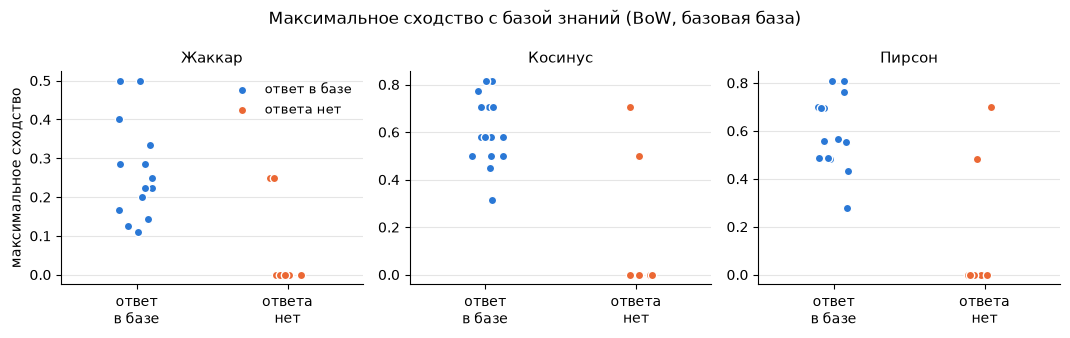

In [10]:
def plot_top1_distribution(retriever, metrics, test, title):
    # Точечная диаграмма максимального сходства: вопросы из базы vs вопросы без ответа
    fig, axes = plt.subplots(1, len(metrics), figsize=(3.6 * len(metrics), 3.4), sharey=False)
    rng = np.random.default_rng(0)
    for ax, m in zip(np.atleast_1d(axes), metrics):
        for k, (label, color, cond) in enumerate([("ответ в базе", "#2a78d6", lambda t: t is not None),
                                                  ("ответа нет", "#eb6834", lambda t: t is None)]):
            vals = [retriever.rank(q, m)[0][1] for q, t in test if cond(t)]
            ax.scatter(k + rng.uniform(-0.12, 0.12, len(vals)), vals, s=36, color=color,
                       edgecolor="white", linewidth=1, label=label, zorder=3)
        ax.set_xticks([0, 1], ["ответ\nв базе", "ответа\nнет"])
        ax.set_xlim(-0.5, 1.5)
        ax.set_title(METRIC_NAMES[m], fontsize=11)
        ax.grid(axis="y", color="#e5e5e5", linewidth=0.8, zorder=0)
        for side in ["top", "right"]:
            ax.spines[side].set_visible(False)
    np.atleast_1d(axes)[0].set_ylabel("максимальное сходство")
    np.atleast_1d(axes)[0].legend(frameon=False, fontsize=9, loc="upper right")
    fig.suptitle(title, fontsize=12)
    fig.tight_layout()
    plt.show()

plot_top1_distribution(base_bow, BASE_METRICS, TEST, "Максимальное сходство с базой знаний (BoW, базовая база)")

### 1.7. Выводы по базовой части

**Результаты.** На базовой базе знаний (22 пары, BoW) все три меры дали одинаковую точность: 7 из 15 вопросов, ответ на которые есть в базе (Accuracy top-1 = 0.467). Почти во всех случаях меры ошибаются одинаково, и ошибки объясняются одной и той же причиной — **лексическим несовпадением** вопроса пользователя и вопроса базы:

* синонимы и перефразирование: «закрывается в субботу» ↔ «график работы», «лимит книг» ↔ «сколько книг можно взять», «беспроводной интернет» ↔ «Wi-Fi», «перекусить» ↔ «есть и пить»;
* при отсутствии ключевого слова в запросе решение определяют общие слова («книга», «библиотека», «сколько»), которые встречаются во многих вопросах базы, поэтому выигрывает случайный вопрос, совпавший по такому слову.

Для вопросов вне базы порога нет, и система всегда выдаёт какой-то ответ. Для пяти из семи таких вопросов сходство равно нулю (нет общих лемм), а два «коварных» вопроса («Можно ли взять ноутбук в библиотеке?», «Как записаться в спортивную секцию?») получили высокое сходство (косинус 0.50 и 0.71) за счёт общих слов «взять», «библиотека», «записаться».

**Сравнение мер.**

* По доле верных ответов меры равны. Различие проявляется в **уверенности ранжирования**: средний отрыв лучшего интента от второго у косинуса и Пирсона (≈0.25) вдвое больше, чем у Жаккара (≈0.12), т. е. правильный ответ отделяется от конкурентов надёжнее. Поэтому в качестве основной меры базовой части предпочтительна **косинусная мера**.
* **Корреляция Пирсона практически совпадает с косинусом.** Векторы очень разреженные (в словаре 61 лемма, в вопросе 2–5 лемм), их среднее близко к нулю, и центрирование почти не меняет вектор; корреляция лишь немного ниже косинуса и в одном случае выбрала другой (тоже неверный) ответ.
* **Мера Жаккара** имеет более «строгую» шкалу (максимальное сходство вопросов из базы 0.11–0.50) и наименьшее сходство для вопросов вне базы (в среднем 0.07), поэтому она хорошо подходит для отсечения нерелевантных вопросов, но хуже различает близкие интенты.

**Почему косинус лучше работает на длинных текстах, а Жаккар — на коротких.**

* Жаккар учитывает только факт вхождения слова (есть/нет) и делит пересечение на **объединение** множеств. В длинном тексте много уникальных слов, объединение быстро растёт, и даже содержательно близкие тексты получают малое значение; повторение ключевого термина (признак темы текста) никак не учитывается.
* Косинус работает с частотами (в TF-IDF — с весами), а нормировка на длину вектора компенсирует разную длину текстов. В длинном тексте частоты и веса несут информацию: важные для темы слова повторяются и/или редки в коллекции, поэтому их вклад в скалярное произведение велик, а «случайные» слова дают малый вклад и не «размывают» сходство так сильно, как в знаменателе Жаккара.
* В коротком тексте (2–5 слов) каждое слово встречается один раз, векторы фактически бинарные, и информация о частоте отсутствует. Тогда $\cos = \frac{C}{\sqrt{A\cdot B}}$ и $K_J = \frac{C}{A+B-C}$ — обе меры возрастают с числом общих слов $C$ и убывают с длинами, т. е. несут одну и ту же информацию. Жаккар при этом проще, интерпретируемее («доля общих слов») и строже наказывает несовпадения, а совпадение даже одного ключевого слова в коротком тексте — сильный сигнал.
* Этим объясняется и полученный результат: все вопросы базы короткие, поэтому выборы трёх мер почти всегда совпадают.

---
## Шаг 2. Дополнительная часть (+1 балл)

### 2.1. Векторизация TF-IDF

Вес термина $t$ в документе $d$ вычисляется как
$$\text{tf-idf}(t,d) = \text{tf}(t,d)\cdot \text{idf}(t),\qquad \text{idf}(t) = \ln\frac{1+N}{1+\text{df}(t)} + 1,$$
где $N$ — число документов (вопросов базы), $\text{df}(t)$ — число документов, содержащих $t$ (сглаженный вариант scikit-learn). Векторы нормируются по $L_2$. Редкие, специфичные для одного вопроса слова получают больший вес, а слова, встречающиеся во многих вопросах (например, «библиотека», «книга»), — меньший.

Ниже TF-IDF применяется к той же базовой базе знаний; результаты сравниваются с BoW в п. 2.4.

In [11]:
base_tfidf = Retriever(BASE_KB["Вопрос"], BASE_KB["intent"], "tfidf")
display(comparison_table(base_tfidf, BASE_METRICS, TEST)[["Вопрос", "Жаккар", "Косинус", "Пирсон"]])
display(score_stats(base_tfidf, BASE_METRICS, TEST).round(3))

,Вопрос,Жаккар,Косинус,Пирсон
0,Во сколько закрывается библиотека в субботу?,0.200 · запись в библиотеку ✗,0.493 · лимит книг ✗,0.471 · лимит книг ✗
1,Как оформить читательский билет первокурснику?,0.125 · оформление списка литературы ✗,0.485 · оформление списка литературы ✗,0.471 · оформление списка литературы ✗
2,Сколько дней можно не сдавать художественную книгу?,0.286 · лимит книг ✗,0.625 · лимит книг ✗,0.610 · лимит книг ✗
3,Какой лимит на количество книг у одного читателя?,0.167 · срок выдачи книг ✗,0.491 · межбиблиотечный абонемент ✗,0.478 · межбиблиотечный абонемент ✗
4,Можно ли продлить учебник через личный кабинет?,0.143 · продление книг ✓,0.593 · продление книг ✓,0.584 · продление книг ✓
5,Сколько стоит каждый день задержки возврата книги?,0.222 · лимит книг ✗,0.493 · лимит книг ✗,0.464 · лимит книг ✗
6,"Я потерял библиотечную книгу, как быть?",0.500 · утеря книги ✓,0.750 · утеря книги ✓,0.741 · утеря книги ✓
7,Можно взять домой журнал из читального зала?,0.286 · издания читального зала ✓,0.578 · издания читального зала ✓,0.553 · издания читального зала ✓
8,Как зайти в электронные базы данных не из университета?,0.111 · электронные ресурсы ✓,0.358 · электронные ресурсы ✓,0.325 · электронные ресурсы ✓
9,Есть ли беспроводной интернет в библиотеке?,0.250 · запись в библиотеку ✗,0.465 · межбиблиотечный абонемент ✗,0.452 · межбиблиотечный абонемент ✗


,Верных ответов (из базы),Accuracy top-1 (из базы),Ср. сходство top-1 (из базы),Ср. сходство top-1 (нет в базе),Ср. отрыв top-1 от top-2
Мера,,,,,
Жаккар,7/15,0.467,0.259,0.071,0.117
Косинус,7/15,0.467,0.582,0.198,0.335
Пирсон,7/15,0.467,0.566,0.195,0.346


### 2.2. Расширение базы знаний

К каждому интенту добавлены 2–3 инвариантные (перефразированные) формулировки вопроса и альтернативный вариант ответа. Поиск ведётся по всем формулировкам, а сходство интента равно максимуму сходства по его формулировкам.

In [12]:
EXT_Q = [(q, it["id"]) for it in INTENTS for q in it["questions"]]
EXT_QUESTIONS, EXT_INTENTS = zip(*EXT_Q)
print(f"Расширенная база: {len(INTENTS)} интентов, {len(EXT_QUESTIONS)} формулировок вопросов, "
      f"{sum(len(it['answers']) for it in INTENTS)} вариантов ответов")

display(pd.DataFrame([{"Тема": it["title"], "Формулировки вопроса": " | ".join(it["questions"]),
                       "Варианты ответа": len(it["answers"])} for it in INTENTS[:5]]))

ext_bow = Retriever(EXT_QUESTIONS, EXT_INTENTS, "bow")
ext_tfidf = Retriever(EXT_QUESTIONS, EXT_INTENTS, "tfidf")
print("Размер словаря расширенной базы:", len(ext_tfidf.index.vocab))

Расширенная база: 22 интентов, 68 формулировок вопросов, 44 вариантов ответов


,Тема,Формулировки вопроса,Варианты ответа
0,график работы,Каков график работы библиотеки? | Во сколько открывается библиотека? | До какого часа работает библиотека?...,2
1,запись в библиотеку,Как записаться в библиотеку? | Что нужно для получения читательского билета? | Как стать читателем библиот...,2
2,срок выдачи книг,На какой срок выдаются книги? | Сколько дней можно держать книгу? | На сколько времени дают учебники?,2
3,лимит книг,Сколько книг можно взять одновременно? | Какое максимальное количество книг выдают на руки? | Есть ли огра...,2
4,продление книг,"Как продлить срок возврата книги? | Можно ли продлить книгу онлайн? | Что делать, если не успеваю вернуть ...",2


Размер словаря расширенной базы: 149


### 2.3. Диалоговый режим с порогом чувствительности

Класс `LibraryBot` хранит базу знаний, строит индекс и отвечает на вопросы. Ответ выдаётся только для интентов, сходство с которыми не ниже **порога чувствительности**. Поддерживаются два режима:

* `all` — выдаются все варианты ответов всех интентов, прошедших порог (по убыванию сходства);
* `random` — из сформированного множества ответов выбирается один случайный.

Если ни один интент не прошёл порог, формируется вежливый отказ с рекомендациями (переформулировать вопрос, обратиться к библиотекарю) и, при наличии, подсказкой о близких темах.

В диалоге поддерживаются команды: `/все`, `/случайный` — смена режима; `/порог 0.4` — изменение порога; `выход` — завершение. Класс сразу проектируется с заделом под шаг 3 (обучение, выбор метрики, пороги по метрикам), методы шага 3 добавляются к нему ниже.

Порог для демонстрации (косинус TF-IDF, 0.35) выбран ориентировочно по распределению сходства из п. 1.6: у вопросов без ответа максимальное сходство чаще всего близко к нулю, а у вопросов из базы, как правило, превышает 0.4. Строгий подбор порогов по валидационной выборке выполняется в п. 3.3.

In [13]:
import copy

class LibraryBot:
    def __init__(self, intents, weighting="tfidf", metric="cosine", thresholds=None, seed=42):
        self.kb = {it["id"]: {"title": it["title"], "questions": list(it["questions"]),
                              "answers": list(it["answers"])} for it in copy.deepcopy(intents)}
        self.weighting = weighting
        self.metric = metric                      # конкретная метрика или 'auto' (шаг 3.2)
        self.thresholds = dict(thresholds or {"cosine": 0.35})
        self.rng = random.Random(seed)
        self.rebuild()

    def rebuild(self):
        pairs = [(q, iid) for iid, it in self.kb.items() for q in it["questions"]]
        questions, intents = zip(*pairs)
        self.retriever = Retriever(questions, intents, self.weighting)

    # ---------- поиск ----------
    def select_metric(self, query):
        return (self.metric, "задана явно") if self.metric != "auto" else self.choose_metric(query)

    def rank(self, query, metric=None):
        return self.retriever.rank(query, metric or self.select_metric(query)[0])

    def find(self, query):
        metric, reason = self.select_metric(query)
        thr = self.thresholds.get(metric, 0.0)
        ranking = self.retriever.rank(query, metric)
        return [(i, s) for i, s in ranking if s >= thr], ranking, metric, reason

    def predict(self, query):
        # Решение для оценки качества: интент лучшего ответа или None (отказ)
        found, ranking, *_ = self.find(query)
        return (found[0][0] if found else None), ranking

    # ---------- ответ ----------
    def reply(self, query, mode="all", verbose=False):
        found, ranking, metric, reason = self.find(query)
        info = f"  [метрика: {METRIC_NAMES[metric]} ({reason}), порог {self.thresholds.get(metric, 0):.3f}, " \
               f"лучшее сходство {ranking[0][1]:.3f}]" if verbose else ""
        if not found:
            hint = ", ".join(f"«{self.kb[i]['title']}»" for i, s in ranking[:2] if s > 0)
            text = ("К сожалению, ответ на этот вопрос в базе знаний не найден. "
                    "Рекомендуется переформулировать вопрос или обратиться к дежурному библиотекарю на абонементе.")
            if hint:
                text += f" Возможно, вопрос относится к темам: {hint}."
            return text + info
        answers = [(i, s, a) for i, s in found for a in self.kb[i]["answers"]]
        if mode == "random":
            i, s, a = self.rng.choice(answers)
            return a + info
        lines = [f"Найдено ответов: {len(answers)} (тем: {len(found)})"]
        lines += [f"  • [{self.kb[i]['title']}, сходство {s:.2f}] {a}" for i, s, a in answers]
        return "\n".join(lines) + info


def run_dialog(bot, inputs=None, verbose=False):
    # Диалог с ботом. inputs=None — живой ввод через input(); иначе — заранее заданные реплики
    mode = "all"
    source = iter(inputs) if inputs is not None else iter(lambda: input("Пользователь: "), None)
    print("Бот: Здравствуйте! Задайте вопрос о правилах библиотеки (команды: /все, /случайный, /порог X, выход).")
    for text in source:
        if inputs is not None:
            print(f"\nПользователь: {text}")
        cmd = text.strip().lower()
        if cmd in {"выход", "exit", "quit", ""}:
            print("Бот: До свидания!")
            break
        if cmd == "/все":
            mode = "all"; print("Бот: режим — все ответы выше порога."); continue
        if cmd == "/случайный":
            mode = "random"; print("Бот: режим — один случайный ответ."); continue
        if cmd.startswith("/порог"):
            try:
                value = float(cmd.split()[1].replace(",", "."))
                metric = bot.metric if bot.metric != "auto" else "cosine"
                bot.thresholds[metric] = value
                print(f"Бот: порог для меры «{METRIC_NAMES[metric]}» = {value}.")
            except (IndexError, ValueError):
                print("Бот: укажите число, например: /порог 0.4")
            continue
        print("Бот:", bot.reply(text, mode, verbose))

bot2 = LibraryBot(INTENTS, weighting="tfidf", metric="cosine", thresholds={"cosine": 0.35})
run_dialog(bot2, [
    "Сколько книг можно взять домой?",
    "Где распечатать курсовую?",
    "/случайный",
    "Где распечатать курсовую?",
    "Где распечатать курсовую?",
    "Где распечатать курсовую?",
    "Как поступить в магистратуру?",
    "/порог 0.15",
    "/все",
    "Можно ли взять книгу домой?",
    "выход",
], verbose=True)

Бот: Здравствуйте! Задайте вопрос о правилах библиотеки (команды: /все, /случайный, /порог X, выход).

Пользователь: Сколько книг можно взять домой?
Бот: Найдено ответов: 4 (тем: 2)
  • [лимит книг, сходство 0.63] Одновременно на руках у читателя может находиться не более 10 изданий.
  • [лимит книг, сходство 0.63] Лимит выдачи — 10 изданий на одного читателя.
  • [издания читального зала, сходство 0.37] Издания читального зала выдаются только для работы в зале, выносить их запрещено.
  • [издания читального зала, сходство 0.37] Книги и журналы читального зала на дом не выдаются.  [метрика: Косинус (задана явно), порог 0.350, лучшее сходство 0.627]

Пользователь: Где распечатать курсовую?
Бот: Найдено ответов: 2 (тем: 1)
  • [печать и сканирование, сходство 0.58] В зале самообслуживания есть принтеры и сканеры; печать стоит 5 рублей за страницу, сканирование бесплатное.
  • [печать и сканирование, сходство 0.58] Печать и сканирование доступны в зале самообслуживания: печать — 5 рублей 

Живой диалог запускается установкой флага `INTERACTIVE = True` (ячейка отключена по умолчанию, чтобы ноутбук выполнялся целиком без ожидания ввода).

In [14]:
INTERACTIVE = False
if INTERACTIVE:
    run_dialog(LibraryBot(INTENTS, weighting="tfidf", metric="cosine", thresholds={"cosine": 0.35}), verbose=True)

### 2.4. Сравнение Bag of Words и TF-IDF

**Какие слова TF-IDF понижает, а какие повышает.** Чтобы увидеть эффект на служебных словах, idf дополнительно вычисляется по текстам расширенной базы **без удаления стоп-слов** (в основном конвейере предлоги и частицы уже удалены, поэтому TF-IDF «доделывает» эту работу для слов, которых нет в стоп-листе, но которые встречаются во многих вопросах).

In [15]:
raw_docs = [[lemma(t) for t in tokenize(q)] for q in EXT_QUESTIONS]
raw_tfidf = TfidfVectorizer(analyzer=identity).fit(raw_docs)
idf_raw = pd.Series(raw_tfidf.idf_, index=raw_tfidf.get_feature_names_out()).sort_values()
df_raw = pd.Series(Counter(t for d in raw_docs for t in set(d)))

idf_ext = pd.Series(ext_tfidf.index.vectorizer.idf_, index=ext_tfidf.index.vocab).sort_values()

low = pd.DataFrame({"слово": idf_raw.index[:12], "idf": idf_raw.values[:12],
                    "в скольких вопросах": df_raw[idf_raw.index[:12]].values})
high = pd.DataFrame({"слово": idf_ext.index[-12:][::-1], "idf": idf_ext.values[-12:][::-1]})
print(f"Всего вопросов (документов): {len(raw_docs)}; idf в BoW для любого слова фактически равен 1.")
display(Markdown("**Слова с наименьшим idf (без удаления стоп-слов) — их вес TF-IDF занижает:**"))
display(low.round(3))
display(Markdown("**Слова с наибольшим idf (основной конвейер) — уникальные термины, вес повышается:**"))
display(high.round(3))

Всего вопросов (документов): 68; idf в BoW для любого слова фактически равен 1.


**Слова с наименьшим idf (без удаления стоп-слов) — их вес TF-IDF занижает:**

,слово,idf,в скольких вопросах
0,библиотека,1.902,27
1,в,1.938,26
2,ли,1.938,26
3,книга,2.099,22
4,как,2.401,16
5,можно,2.462,15
6,где,3.155,7
7,есть,3.155,7
8,какой,3.155,7
9,что,3.155,7


**Слова с наибольшим idf (основной конвейер) — уникальные термины, вес повышается:**

,слово,idf
0,экземпляр,4.541
1,штраф,4.541
2,хранить,4.541
3,час,4.541
4,число,4.541
5,телефон,4.541
6,университет,4.541
7,удаленный,4.541
8,хранение,4.541
9,учебник,4.541


In [16]:
def explain_query(query, retriever_bow, retriever_tfidf, top=3):
    tokens = preprocess(query)
    v_bow = retriever_bow.index.transform(tokens)
    v_tf = retriever_tfidf.index.transform(tokens)
    vocab = retriever_tfidf.index.vocab
    weights = pd.DataFrame({"BoW": v_bow, "TF-IDF": v_tf}, index=vocab)
    weights = weights[(weights != 0).any(axis=1)]
    display(Markdown(f"**Запрос:** «{query}» → леммы {tokens}"))
    display(weights.round(3).T)
    rows = []
    for name, r in [("BoW", retriever_bow), ("TF-IDF", retriever_tfidf)]:
        for k, (i, s) in enumerate(r.rank(query, "cosine")[:top], 1):
            rows.append({"Векторизация": name, "Место": k, "Тема": TITLE[i], "Косинус": round(s, 3)})
    display(pd.DataFrame(rows).pivot(index="Место", columns="Векторизация", values=["Тема", "Косинус"]))

explain_query("Можно ли взять домой журнал из читального зала?", ext_bow, ext_tfidf)
explain_query("Есть ли беспроводной интернет в библиотеке?", ext_bow, ext_tfidf)

**Запрос:** «Можно ли взять домой журнал из читального зала?» → леммы ['взять', 'домой', 'журнал', 'читальный', 'зал']

,взять,домой,зал,читальный
BoW,1.000,1.000,1.000,1.000
TF-IDF,0.537,0.589,0.427,0.427


Тема                          Косинус       
Векторизация                      BoW                   TF-IDF     BoW TF-IDF
Место                                                                        
1             издания читального зала  издания читального зала   0.612   0.61
2                       еда и напитки            еда и напитки   0.447  0.314
3                   тишина и телефоны        тишина и телефоны   0.447  0.307

**Запрос:** «Есть ли беспроводной интернет в библиотеке?» → леммы ['беспроводный', 'интернет', 'библиотека']

,беспроводный,библиотека,интернет
BoW,1.000,1.000,1.000
TF-IDF,0.678,0.284,0.678


Тема                            Косинус       
Векторизация                    BoW                     TF-IDF     BoW TF-IDF
Место                                                                        
1                             Wi-Fi                      Wi-Fi   0.667   0.54
2               запись в библиотеку              еда и напитки   0.408  0.119
3             печать и сканирование  межбиблиотечный абонемент   0.408  0.117

In [17]:
def topk_stats(retriever, metric, test):
    ok1, ok3, margins = [], [], []
    for q, true in test:
        if true is None:
            continue
        ranking = retriever.rank(q, metric)
        ids = [i for i, _ in ranking]
        ok1.append(ids[0] == true)
        ok3.append(true in ids[:3])
        pos = ids.index(true)
        rival = ranking[1][1] if pos == 0 else ranking[0][1]
        margins.append(ranking[pos][1] - rival)
    return np.mean(ok1), np.mean(ok3), np.mean(margins)

rows = []
for kb_name, r_bow, r_tf in [("базовая", base_bow, base_tfidf), ("расширенная", ext_bow, ext_tfidf)]:
    for m in ["cosine", "pearson"]:
        for w_name, r in [("BoW", r_bow), ("TF-IDF", r_tf)]:
            a1, a3, mg = topk_stats(r, m, TEST)
            rows.append({"База": kb_name, "Мера": METRIC_NAMES[m], "Векторизация": w_name,
                         "Top-1": a1, "Top-3": a3, "Ср. отрыв правильного ответа": mg})
cmp_24 = pd.DataFrame(rows)
display(cmp_24.round(3))

,База,Мера,Векторизация,Top-1,Top-3,Ср. отрыв правильного ответа
0,базовая,Косинус,BoW,0.467,0.733,0.015
1,базовая,Косинус,TF-IDF,0.467,0.733,0.004
2,базовая,Пирсон,BoW,0.467,0.733,0.016
3,базовая,Пирсон,TF-IDF,0.467,0.733,0.006
4,расширенная,Косинус,BoW,0.733,0.867,0.109
5,расширенная,Косинус,TF-IDF,0.733,0.933,0.135
6,расширенная,Пирсон,BoW,0.733,0.933,0.111
7,расширенная,Пирсон,TF-IDF,0.733,0.933,0.137


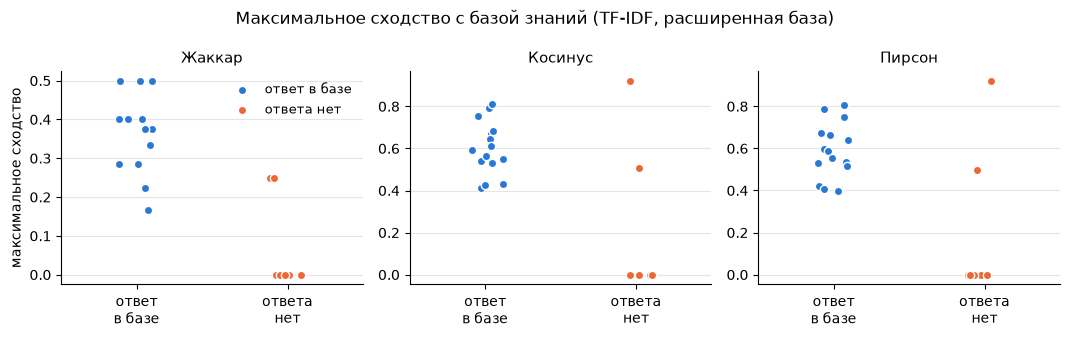

In [18]:
plot_top1_distribution(ext_tfidf, ["jaccard", "cosine", "pearson"], TEST,
                       "Максимальное сходство с базой знаний (TF-IDF, расширенная база)")

**Выводы по сравнению BoW и TF-IDF.**

* **TF-IDF занизил вес частых слов.** Если не удалять стоп-слова, минимальный idf получают «библиотека» (встречается в 27 из 68 вопросов), предлоги и частицы «в», «ли» (по 26), «книга» (22), «как», «можно». Даже в основном конвейере, где служебные слова уже удалены, вес слов «библиотека», «книга», «читальный», «зал» заметно ниже веса специфичных слов (например, для запроса «Есть ли беспроводной интернет в библиотеке?» вес «библиотека» 0.28 против 0.68 у «беспроводный» и «интернет»).
* **TF-IDF повысил вес уникальных терминов**: «штраф», «тишина», «телефон», «учебник», «фонд», «экземпляр» и др. встречаются в одном вопросе и получают максимальный idf (4.54).
* **Влияние на ранжирование.** Правильный интент сильнее отрывается от конкурентов: на запросе про Wi-Fi второй по сходству интент при BoW набирал 0.41 (совпадение только по слову «библиотека»), а при TF-IDF — 0.12; на расширенной базе средний отрыв правильного ответа вырос с 0.109 до 0.135, а Top-3 для косинуса — с 0.867 до 0.933. Доля верных top-1 ответов при этом не изменилась (0.733).
* **На базовой базе (22 коротких вопроса) TF-IDF не помог** (top-1 = 0.467 в обоих случаях): при малом числе документов idf оценивается грубо, и «случайно редкое» слово получает такой же высокий вес, как действительно важный термин (например, «Какой лимит на количество книг…» был отнесён к межбиблиотечному абонементу).
* **Побочный эффект TF-IDF** — рост ложных срабатываний на вопросах вне базы, совпадающих по одному редкому слову: «Как записаться в спортивную секцию?» получает косинус 0.92 с вопросом «Как записаться в библиотеку?», поскольку редкое слово «записаться» получает большой вес.
* Наибольший прирост качества дало не взвешивание, а **расширение базы перефразировками** (п. 2.2): top-1 вырос с 0.467 до 0.733, Top-3 — до 0.87–0.93.

### 2.5. Поиск с использованием коэффициента Спирмена

Коэффициент ранговой корреляции Спирмена — это коэффициент Пирсона, вычисленный по рангам значений:
$$\rho = 1 - \frac{6\sum d_i^2}{n(n^2-1)}$$
(формула верна при отсутствии связанных рангов; в векторах текстов почти все координаты нулевые и образуют одну большую группу связанных рангов, поэтому используется общий вариант — корреляция Пирсона между средними рангами, как в `scipy.stats.spearmanr`).

In [19]:
rows = []
for kb_name, r_bow, r_tf in [("базовая", base_bow, base_tfidf), ("расширенная", ext_bow, ext_tfidf)]:
    for w_name, r in [("BoW", r_bow), ("TF-IDF", r_tf)]:
        for m in ["cosine", "pearson", "spearman"]:
            a1, a3, mg = topk_stats(r, m, TEST)
            rows.append({"База": kb_name, "Векторизация": w_name, "Мера": METRIC_NAMES[m],
                         "Top-1": a1, "Top-3": a3, "Ср. отрыв": mg})
cmp_25 = pd.DataFrame(rows)
display(cmp_25.pivot_table(index=["База", "Векторизация"], columns="Мера", values=["Top-1", "Top-3"]).round(3))

# Совпадение рангов Спирмена и Пирсона на BoW (векторы из 0/1)
same = np.mean([np.isclose(ext_bow.scores(q, "pearson"), ext_bow.scores(q, "spearman")).all() for q, _ in TEST])
print(f"Доля тестовых запросов, для которых на BoW сходство Спирмена совпадает с Пирсоном: {same:.2f}")

Top-1                  Top-3               
Мера                     Косинус Пирсон Спирмен Косинус Пирсон Спирмен
База        Векторизация                                              
базовая     BoW            0.467  0.467   0.467   0.733  0.733   0.733
            TF-IDF         0.467  0.467   0.467   0.733  0.733   0.667
расширенная BoW            0.733  0.733   0.733   0.867  0.933   0.867
            TF-IDF         0.733  0.733   0.733   0.933  0.933   0.933

Доля тестовых запросов, для которых на BoW сходство Спирмена совпадает с Пирсоном: 1.00


In [20]:
display(comparison_table(ext_tfidf, ["cosine", "pearson", "spearman"], TEST)
        [["Вопрос", "Косинус", "Пирсон", "Спирмен"]])

,Вопрос,Косинус,Пирсон,Спирмен
0,Во сколько закрывается библиотека в субботу?,0.670 · график работы ✓,0.665 · график работы ✓,0.808 · график работы ✓
1,Как оформить читательский билет первокурснику?,0.645 · обходной лист ✗,0.638 · обходной лист ✗,0.655 · обходной лист ✗
2,Сколько дней можно не сдавать художественную книгу?,0.792 · срок выдачи книг ✓,0.787 · срок выдачи книг ✓,0.857 · срок выдачи книг ✓
3,Какой лимит на количество книг у одного читателя?,0.414 · лимит книг ✓,0.399 · лимит книг ✓,0.499 · лимит книг ✓
4,Можно ли продлить учебник через личный кабинет?,0.429 · продление книг ✓,0.420 · продление книг ✓,0.396 · продление книг ✓
5,Сколько стоит каждый день задержки возврата книги?,0.548 · срок выдачи книг ✗,0.535 · срок выдачи книг ✗,0.648 · срок выдачи книг ✗
6,"Я потерял библиотечную книгу, как быть?",0.810 · утеря книги ✓,0.807 · утеря книги ✓,0.814 · утеря книги ✓
7,Можно взять домой журнал из читального зала?,0.610 · издания читального зала ✓,0.597 · издания читального зала ✓,0.600 · издания читального зала ✓
8,Как зайти в электронные базы данных не из университета?,0.530 · электронные ресурсы ✓,0.517 · электронные ресурсы ✓,0.493 · электронные ресурсы ✓
9,Есть ли беспроводной интернет в библиотеке?,0.540 · Wi-Fi ✓,0.532 · Wi-Fi ✓,0.655 · Wi-Fi ✓


**Выводы по коэффициенту Спирмена.**

* Доля верных top-1 ответов при поиске по Спирмену совпала с косинусом и Пирсоном во всех конфигурациях (0.467 на базовой базе, 0.733 на расширенной), т. е. качество поиска существенно не изменилось.
* **На BoW коэффициент Спирмена в точности равен коэффициенту Пирсона** (совпадение для 100 % запросов): векторы вопросов состоят из 0 и 1, а переход к рангам для двухзначного вектора — линейное преобразование, которое корреляция Пирсона не замечает.
* На TF-IDF Спирмен отличается от Пирсона: он учитывает только порядок весов, а не их величину. Почти все координаты нулевые и образуют одну группу связанных рангов, поэтому значение определяется в основном совпадением множеств ненулевых координат, а различие в весах слов частично теряется. Из-за этого значения сходства у Спирмена выше и «сжаты» (например, 0.81 против 0.67 у косинуса для вопроса о графике работы), а на базовой базе Top-3 снизился с 0.733 до 0.667.
* Преимущество ранговой корреляции — устойчивость к выбросам — для нормированных векторов TF-IDF малозначимо: веса ограничены и выбросов не содержат. Поэтому для текстовых векторов Спирмен не даёт выигрыша по сравнению с косинусом, но и не ухудшает поиск лучшего ответа; некоторое различие проявляется лишь при использовании порогов (см. п. 3.5).

---
## Шаг 3. Дополнительная часть (+1 балл)

### 3.1. Обучение системы

Добавляются методы:

* `add_intent` — новый интент (тема) с вопросами и ответами;
* `add_question` — новая формулировка вопроса к существующему интенту;
* `add_answer` — дополнительный вариант ответа к существующему интенту;
* `learn(question, answer, intent_id=None)` — универсальный метод: если указан существующий интент или ответ уже есть в базе, вопрос (и, при необходимости, ответ) присоединяется к этому интенту, иначе создаётся новый интент.

После каждого изменения индекс перестраивается (`rebuild`), так что словарь и веса idf пересчитываются.

In [21]:
def add_intent(self, intent_id, title, questions, answers):
    if intent_id in self.kb:
        raise ValueError(f"Интент {intent_id} уже существует")
    self.kb[intent_id] = {"title": title, "questions": list(questions), "answers": list(answers)}
    TITLE.setdefault(intent_id, title)
    self.rebuild()

def add_question(self, intent_id, question):
    if question not in self.kb[intent_id]["questions"]:
        self.kb[intent_id]["questions"].append(question)
        self.rebuild()

def add_answer(self, intent_id, answer):
    if answer not in self.kb[intent_id]["answers"]:
        self.kb[intent_id]["answers"].append(answer)

def learn(self, question, answer, intent_id=None, title=None):
    if intent_id is None:
        intent_id = next((i for i, it in self.kb.items() if answer in it["answers"]), None)
    if intent_id in self.kb:
        self.add_answer(intent_id, answer)
        self.add_question(intent_id, question)
        return f"Вопрос добавлен к теме «{self.kb[intent_id]['title']}»"
    new_id = intent_id or f"user_{len(self.kb) + 1}"
    self.add_intent(new_id, title or question, [question], [answer])
    return f"Создана новая тема «{title or question}»"

LibraryBot.add_intent, LibraryBot.add_question = add_intent, add_question
LibraryBot.add_answer, LibraryBot.learn = add_answer, learn

bot31 = LibraryBot(INTENTS, weighting="tfidf", metric="cosine", thresholds={"cosine": 0.35})
q_new = "Можно ли взять ноутбук в библиотеке?"
print("До обучения:", bot31.reply(q_new, verbose=True), "\n")

print(bot31.learn(q_new,
                  "Ноутбуки выдаются в читальном зале по читательскому билету на 4 часа для работы в библиотеке.",
                  intent_id="laptops", title="выдача ноутбуков"))
bot31.add_question("laptops", "Выдают ли в библиотеке компьютеры во временное пользование?")
print("После обучения:", bot31.reply("Выдают ли ноутбуки в библиотеке?", verbose=True), "\n")

print(bot31.learn("Как вернуть книгу, если библиотека закрыта?",
                  "Если библиотека закрыта, книгу можно опустить в ящик возврата у главного входа.",
                  intent_id="renewal"))
bot31.add_answer("max_books", "Аспиранты и преподаватели могут взять до 20 изданий одновременно.")
print("Ответ с новым вариантом:", bot31.reply("Сколько книг можно взять одновременно?"))

До обучения: Найдено ответов: 2 (тем: 1)
  • [лимит книг, сходство 0.51] Одновременно на руках у читателя может находиться не более 10 изданий.
  • [лимит книг, сходство 0.51] Лимит выдачи — 10 изданий на одного читателя.  [метрика: Косинус (задана явно), порог 0.350, лучшее сходство 0.505] 

Создана новая тема «выдача ноутбуков»
После обучения: Найдено ответов: 1 (тем: 1)
  • [выдача ноутбуков, сходство 0.60] Ноутбуки выдаются в читальном зале по читательскому билету на 4 часа для работы в библиотеке.  [метрика: Косинус (задана явно), порог 0.350, лучшее сходство 0.601] 

Вопрос добавлен к теме «продление книг»
Ответ с новым вариантом: Найдено ответов: 3 (тем: 1)
  • [лимит книг, сходство 1.00] Одновременно на руках у читателя может находиться не более 10 изданий.
  • [лимит книг, сходство 1.00] Лимит выдачи — 10 изданий на одного читателя.
  • [лимит книг, сходство 1.00] Аспиранты и преподаватели могут взять до 20 изданий одновременно.


### 3.2. Автоматический выбор метрики

Правило выбора опирается на два признака запроса.

1. **Длина запроса** (число лемм после предобработки). Для коротких запросов (≤ 3 лемм) базовой считается мера Жаккара: в коротком тексте каждое слово встречается один раз, частоты не несут информации, а совпадение даже одного ключевого слова — сильный сигнал. Для длинных запросов базовой считается косинусная мера по TF-IDF, которая учитывает веса слов и меньше штрафует за «лишние» слова.
2. **Разброс (согласованность) метрик.** Для запроса вычисляются ранжирования по всем четырём мерам.
   * Если все меры выбрали один и тот же интент — используется базовая мера по длине.
   * Если меры расходятся, используется мера с наибольшей **относительной уверенностью** — отрывом лучшего интента от второго, нормированным на порог этой меры: $\text{conf}_m = (s_1 - s_2)\,/\,\max(\text{thr}_m, 0.05)$. Нормировка нужна, так как шкалы мер различаются (сходство Жаккара обычно меньше косинуса). Среди мер, поддержавших интент большинства, предпочтение отдаётся базовой мере.

In [22]:
SHORT_LEN = 3
AUTO_METRICS = ["jaccard", "cosine", "pearson", "spearman"]

def choose_metric(self, query):
    n = len(preprocess(query))
    base = "jaccard" if n <= SHORT_LEN else "cosine"
    rankings = {m: self.retriever.rank(query, m) for m in AUTO_METRICS}
    tops = {m: r[0][0] for m, r in rankings.items()}
    if len(set(tops.values())) == 1:
        return base, f"{n} лемм, меры согласны"
    conf = {m: (r[0][1] - r[1][1]) / max(self.thresholds.get(m, 0.0), 0.05) for m, r in rankings.items()}
    leader, votes = Counter(tops.values()).most_common(1)[0]
    if votes > len(AUTO_METRICS) / 2:
        voters = [m for m in AUTO_METRICS if tops[m] == leader]
        chosen = base if base in voters else max(voters, key=conf.get)
        return chosen, f"{n} лемм, большинство мер ({votes}/4)"
    chosen = max(AUTO_METRICS, key=conf.get)
    return chosen, f"{n} лемм, меры расходятся — макс. уверенность"

LibraryBot.choose_metric = choose_metric

bot32 = LibraryBot(INTENTS, weighting="tfidf", metric="auto",
                   thresholds={"jaccard": 0.0, "cosine": 0.0, "pearson": 0.0, "spearman": 0.0})
rows = []
for q, true in TEST[:8] + TEST[-3:]:
    m, reason = bot32.choose_metric(q)
    tops = {METRIC_NAMES[k]: TITLE[bot32.retriever.rank(q, k)[0][0]] for k in AUTO_METRICS}
    rows.append({"Вопрос": q, "Лемм": len(preprocess(q)), **tops, "Выбрана мера": METRIC_NAMES[m], "Причина": reason})
display(pd.DataFrame(rows))

,Вопрос,Лемм,Жаккар,Косинус,Пирсон,Спирмен,Выбрана мера,Причина
0,Во сколько закрывается библиотека в субботу?,4,график работы,график работы,график работы,график работы,Косинус,"4 лемм, меры согласны"
1,Как оформить читательский билет первокурснику?,4,обходной лист,обходной лист,обходной лист,обходной лист,Косинус,"4 лемм, меры согласны"
2,Сколько дней можно не сдавать художественную книгу?,5,срок выдачи книг,срок выдачи книг,срок выдачи книг,срок выдачи книг,Косинус,"5 лемм, меры согласны"
3,Какой лимит на количество книг у одного читателя?,4,лимит книг,лимит книг,лимит книг,лимит книг,Косинус,"4 лемм, меры согласны"
4,Можно ли продлить учебник через личный кабинет?,4,продление книг,продление книг,продление книг,продление книг,Косинус,"4 лемм, меры согласны"
5,Сколько стоит каждый день задержки возврата книги?,7,срок выдачи книг,срок выдачи книг,срок выдачи книг,срок выдачи книг,Косинус,"7 лемм, меры согласны"
6,"Я потерял библиотечную книгу, как быть?",3,утеря книги,утеря книги,утеря книги,утеря книги,Жаккар,"3 лемм, меры согласны"
7,Можно взять домой журнал из читального зала?,5,издания читального зала,издания читального зала,издания читального зала,издания читального зала,Косинус,"5 лемм, меры согласны"
8,Когда начинается зимняя сессия?,3,график работы,график работы,график работы,график работы,Жаккар,"3 лемм, меры согласны"
9,Можно ли взять ноутбук в библиотеке?,3,запись в библиотеку,лимит книг,лимит книг,запись в библиотеку,Пирсон,"3 лемм, меры расходятся — макс. уверенность"


### 3.3. Минимальные значения (пороги) метрик

Для каждой комбинации «база × векторизация × мера» порог подбирается на **валидационном наборе** `DEV`: перебираются середины между соседними значениями максимального сходства, и выбирается порог, дающий наибольшую долю правильных решений (правильный ответ для вопросов из базы и отказ для вопросов вне базы). При равенстве берётся середина диапазона лучших порогов — так порог менее чувствителен к случайным колебаниям. Если максимальное сходство ниже порога, система сообщает об отсутствии ответа.

In [23]:
def decide(ranking, threshold):
    return ranking[0][0] if ranking[0][1] >= threshold else None

def tune_threshold(retriever, metric, dev):
    cached = [(retriever.rank(q, metric), t) for q, t in dev]
    tops = sorted({r[0][1] for r, _ in cached})
    candidates = [tops[0] - 1e-6] + [(a + b) / 2 for a, b in zip(tops, tops[1:])] + [tops[-1] + 1e-6]
    accs = [np.mean([decide(r, c) == t for r, t in cached]) for c in candidates]
    best = [c for c, a in zip(candidates, accs) if a == max(accs)]
    return float(np.median(best)), max(accs)

RETRIEVERS = {("базовая", "BoW"): base_bow, ("базовая", "TF-IDF"): base_tfidf,
              ("расширенная", "BoW"): ext_bow, ("расширенная", "TF-IDF"): ext_tfidf}
ALL_METRICS = ["jaccard", "cosine", "pearson", "spearman"]

THRESHOLDS = {}
rows = []
for (kb_name, w_name), r in RETRIEVERS.items():
    for m in ALL_METRICS:
        thr, dev_acc = tune_threshold(r, m, DEV)
        THRESHOLDS[(kb_name, w_name, m)] = thr
        rows.append({"База": kb_name, "Векторизация": w_name, "Мера": METRIC_NAMES[m],
                     "Порог": round(thr, 3), "Accuracy на DEV": round(dev_acc, 3)})
display(pd.DataFrame(rows).pivot_table(index=["База", "Векторизация"], columns="Мера", values="Порог").round(3))

Мера                      Жаккар  Косинус  Пирсон  Спирмен
База        Векторизация                                  
базовая     BoW            0.268    0.500   0.485    0.485
            TF-IDF         0.268    0.505   0.493    0.481
расширенная BoW            0.243    0.508   0.499    0.499
            TF-IDF         0.243    0.521   0.516    0.489

In [24]:
ext_thr = {m: THRESHOLDS[("расширенная", "TF-IDF", m)] for m in ALL_METRICS}
bot33 = LibraryBot(INTENTS, weighting="tfidf", metric="auto", thresholds=ext_thr)
for q in ["Можно ли взять ноутбук в библиотеке?", "Как записаться в спортивную секцию?",
          "Как записаться в библиотеку первокурснику?", "Где находится столовая?"]:
    print("Пользователь:", q)
    print("Бот:", bot33.reply(q, mode="random", verbose=True), "\n")

Пользователь: Можно ли взять ноутбук в библиотеке?
Бот: К сожалению, ответ на этот вопрос в базе знаний не найден. Рекомендуется переформулировать вопрос или обратиться к дежурному библиотекарю на абонементе. Возможно, вопрос относится к темам: «лимит книг», «еда и напитки».  [метрика: Пирсон (3 лемм, меры расходятся — макс. уверенность), порог 0.516, лучшее сходство 0.497] 

Пользователь: Как записаться в спортивную секцию?
Бот: Для записи нужно прийти на абонемент со студенческим билетом или пропуском сотрудника; читательский билет оформляется за 10 минут.  [метрика: Жаккар (3 лемм, меры согласны), порог 0.243, лучшее сходство 0.250] 

Пользователь: Как записаться в библиотеку первокурснику?
Бот: Для записи нужно прийти на абонемент со студенческим билетом или пропуском сотрудника; читательский билет оформляется за 10 минут.  [метрика: Жаккар (3 лемм, меры согласны), порог 0.243, лучшее сходство 0.667] 

Пользователь: Где находится столовая?


Бот: К сожалению, ответ на этот вопрос в базе знаний не найден. Рекомендуется переформулировать вопрос или обратиться к дежурному библиотекарю на абонементе.  [метрика: Жаккар (2 лемм, меры согласны), порог 0.243, лучшее сходство 0.000] 



### 3.4. Автоматическая оценка качества

Функция `evaluate` принимает «метод» — функцию, возвращающую для вопроса решение (интент или отказ `None`) и ранжированный список интентов, — и вычисляет:

* **Accuracy** — доля полностью правильных решений на всех тестовых вопросах: для вопроса из базы — выдан ответ нужного интента, для вопроса вне базы — выдан отказ;
* **Top-3 accuracy** — доля вопросов из базы, для которых правильный интент входит в 3 наиболее похожих (порог не учитывается, оценивается качество ранжирования);
* **Precision / Recall / F1** для бинарной классификации «ответ корректен / не корректен» по схеме со слайда: $\text{Precision} = \dfrac{\#\text{корректных выданных ответов}}{\#\text{выданных ответов}}$, $\text{Recall} = \dfrac{\#\text{корректных выданных ответов}}{\#\text{вопросов, ответ на которые есть в базе}}$.

Дополнительно приводится **Accuracy без порога** — доля верных top-1 ответов среди вопросов из базы (это показатель базовой части, где отказ невозможен).

In [25]:
def evaluate(method, test):
    # method(query) -> (решение: интент или None, ранжирование [(интент, сходство), ...])
    correct, top3, top1, answered, answered_ok, n_in = 0, 0, 0, 0, 0, 0
    for q, true in test:
        pred, ranking = method(q)
        ids = [i for i, _ in ranking]
        correct += pred == true
        if pred is not None:
            answered += 1
            answered_ok += pred == true
        if true is not None:
            n_in += 1
            top1 += ids[0] == true
            top3 += true in ids[:3]
    precision = answered_ok / answered if answered else 0.0
    recall = answered_ok / n_in
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return {"Accuracy без порога": top1 / n_in, "Accuracy": correct / len(test), "Top-3": top3 / n_in,
            "Precision": precision, "Recall": recall, "F1": f1}

def threshold_method(retriever, metric, threshold):
    def method(q):
        ranking = retriever.rank(q, metric)
        return decide(ranking, threshold), ranking
    return method

def no_threshold_method(retriever, metric):
    return threshold_method(retriever, metric, -np.inf)

# Пример: базовая часть (BoW, без порога) и тот же метод с порогом
print("BoW + косинус, без порога:", {k: round(v, 3) for k, v in evaluate(no_threshold_method(base_bow, "cosine"), TEST).items()})
print("BoW + косинус, с порогом: ", {k: round(v, 3) for k, v in
      evaluate(threshold_method(base_bow, "cosine", THRESHOLDS[("базовая", "BoW", "cosine")]), TEST).items()})

BoW + косинус, без порога: {'Accuracy без порога': 0.467, 'Accuracy': 0.318, 'Top-3': 0.733, 'Precision': 0.318, 'Recall': 0.467, 'F1': 0.378}
BoW + косинус, с порогом:  {'Accuracy без порога': 0.467, 'Accuracy': 0.545, 'Top-3': 0.733, 'Precision': 0.462, 'Recall': 0.4, 'F1': 0.429}


### 3.5. Сводная таблица и выбор лучшего подхода

Оцениваются все методы из шагов 1–3: две базы знаний (базовая и расширенная), две схемы векторизации, четыре меры сходства, а также автоматический выбор метрики. Мера Жаккара работает с множествами слов и не зависит от схемы взвешивания, поэтому для неё приводится одна строка на базу знаний. Для всех методов используются пороги, подобранные на валидационном наборе (п. 3.3); столбец «Accuracy без порога» показывает качество в постановке базовой части.

In [26]:
results = []
for (kb_name, w_name), r in RETRIEVERS.items():
    for m in ALL_METRICS:
        if m == "jaccard" and w_name == "TF-IDF":
            continue
        thr = THRESHOLDS[(kb_name, w_name, m)]
        res = evaluate(threshold_method(r, m, thr), TEST)
        res["Accuracy без порога"] = evaluate(no_threshold_method(r, m), TEST)["Accuracy без порога"]
        w_label = "множества" if m == "jaccard" else w_name
        results.append({"Метод": f"{METRIC_NAMES[m]} · {w_label} · {kb_name}", "Порог": thr, **res})

for kb_name, intents_src in [("базовая", [{**it, "questions": it["questions"][:1], "answers": it["answers"][:1]} for it in INTENTS]),
                             ("расширенная", INTENTS)]:
    thr = {m: THRESHOLDS[(kb_name, "TF-IDF", m)] for m in ALL_METRICS}
    auto_bot = LibraryBot(intents_src, weighting="tfidf", metric="auto", thresholds=thr)
    res = evaluate(auto_bot.predict, TEST)
    res["Accuracy без порога"] = evaluate(lambda q: (None, auto_bot.rank(q)), TEST)["Accuracy без порога"]
    results.append({"Метод": f"Авто-выбор · TF-IDF · {kb_name}", "Порог": np.nan, **res})

summary = (pd.DataFrame(results).set_index("Метод")
           [["Порог", "Accuracy без порога", "Accuracy", "Top-3", "Precision", "Recall", "F1"]]
           .sort_values(["Accuracy", "F1", "Top-3"], ascending=False))
display(summary.round(3).style.format(precision=3).background_gradient(
    subset=["Accuracy", "F1"], cmap="Blues", vmin=0, vmax=1))

,Порог,Accuracy без порога,Accuracy,Top-3,Precision,Recall,F1
Метод,,,,,,,
Спирмен · TF-IDF · расширенная,0.489,0.733,0.682,0.933,0.643,0.600,0.621
Жаккар · множества · расширенная,0.243,0.733,0.636,0.867,0.643,0.600,0.621
Пирсон · BoW · расширенная,0.499,0.733,0.636,0.933,0.615,0.533,0.571
Косинус · TF-IDF · расширенная,0.521,0.733,0.636,0.933,0.615,0.533,0.571
Пирсон · TF-IDF · расширенная,0.516,0.733,0.636,0.933,0.615,0.533,0.571
Авто-выбор · TF-IDF · расширенная,nan,0.733,0.636,0.933,0.615,0.533,0.571
Косинус · BoW · расширенная,0.508,0.733,0.636,0.867,0.615,0.533,0.571
Спирмен · BoW · расширенная,0.499,0.733,0.636,0.867,0.615,0.533,0.571
Авто-выбор · TF-IDF · базовая,nan,0.467,0.591,0.733,0.667,0.400,0.500


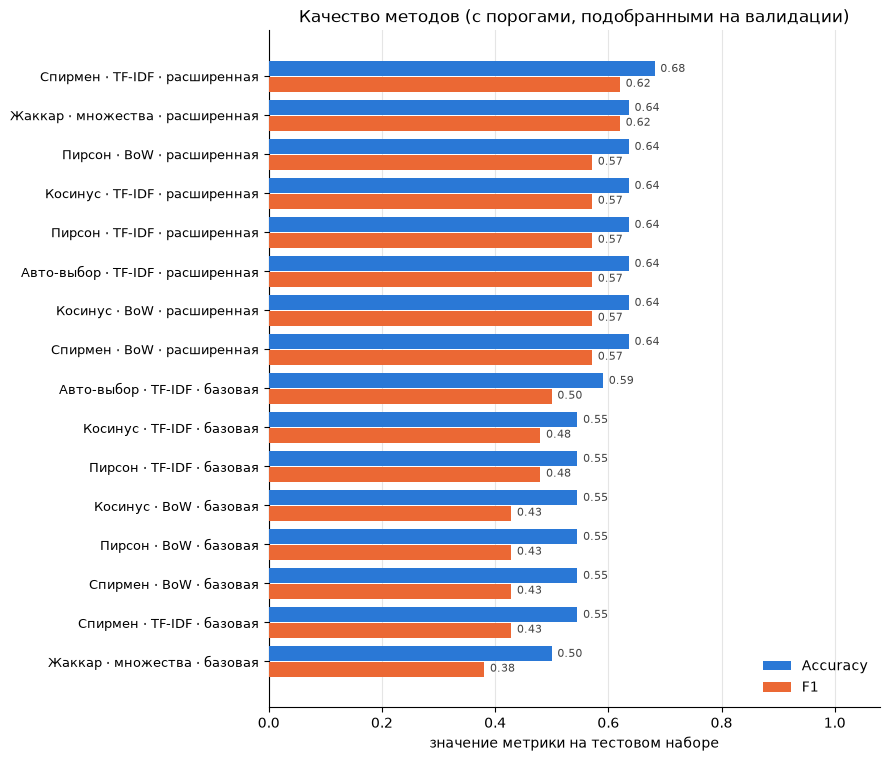

In [27]:
plot_df = summary[["Accuracy", "F1"]].iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 0.42 * len(plot_df) + 1))
y = np.arange(len(plot_df))
h = 0.38
ax.barh(y + h / 2 + 0.01, plot_df["Accuracy"], height=h, color="#2a78d6", label="Accuracy", zorder=3)
ax.barh(y - h / 2 - 0.01, plot_df["F1"], height=h, color="#eb6834", label="F1", zorder=3)
for yi, (acc, f1) in enumerate(plot_df.values):
    ax.text(acc + 0.01, yi + h / 2, f"{acc:.2f}", va="center", fontsize=8, color="#444")
    ax.text(f1 + 0.01, yi - h / 2, f"{f1:.2f}", va="center", fontsize=8, color="#444")
ax.set_yticks(y, plot_df.index, fontsize=9)
ax.set_xlim(0, 1.08)
ax.set_xlabel("значение метрики на тестовом наборе")
ax.grid(axis="x", color="#e5e5e5", linewidth=0.8, zorder=0)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
ax.legend(frameon=False, loc="lower right")
ax.set_title("Качество методов (с порогами, подобранными на валидации)")
fig.tight_layout()
plt.show()

In [28]:
best_name = summary.index[0]
best_row = summary.iloc[0]
display(Markdown(f"**Лучший метод по Accuracy (при равенстве — по F1):** {best_name} — "
                 f"Accuracy = {best_row['Accuracy']:.3f}, Top-3 = {best_row['Top-3']:.3f}, "
                 f"Precision = {best_row['Precision']:.3f}, Recall = {best_row['Recall']:.3f}, F1 = {best_row['F1']:.3f}"))

**Лучший метод по Accuracy (при равенстве — по F1):** Спирмен · TF-IDF · расширенная — Accuracy = 0.682, Top-3 = 0.933, Precision = 0.643, Recall = 0.600, F1 = 0.621

In [29]:
# Разбор ошибок лучшей конфигурации расширенной базы (TF-IDF, авто-выбор)
auto_bot = LibraryBot(INTENTS, weighting="tfidf", metric="auto",
                      thresholds={m: THRESHOLDS[("расширенная", "TF-IDF", m)] for m in ALL_METRICS})
rows = []
for q, true in TEST:
    found, ranking, metric, reason = auto_bot.find(q)
    pred = found[0][0] if found else None
    rows.append({"Вопрос": q, "Верно": "✓" if pred == true else "✗",
                 "Ожидалось": TITLE[true] if true else "отказ",
                 "Получено": TITLE[pred] if pred else "отказ",
                 "Мера": METRIC_NAMES[metric], "Сходство": round(ranking[0][1], 3)})
display(pd.DataFrame(rows))

,Вопрос,Верно,Ожидалось,Получено,Мера,Сходство
0,Во сколько закрывается библиотека в субботу?,✓,график работы,график работы,Косинус,0.670
1,Как оформить читательский билет первокурснику?,✗,запись в библиотеку,обходной лист,Косинус,0.645
2,Сколько дней можно не сдавать художественную книгу?,✓,срок выдачи книг,срок выдачи книг,Косинус,0.792
3,Какой лимит на количество книг у одного читателя?,✗,лимит книг,отказ,Косинус,0.414
4,Можно ли продлить учебник через личный кабинет?,✗,продление книг,отказ,Косинус,0.429
5,Сколько стоит каждый день задержки возврата книги?,✗,штраф за просрочку,срок выдачи книг,Косинус,0.548
6,"Я потерял библиотечную книгу, как быть?",✓,утеря книги,утеря книги,Жаккар,0.500
7,Можно взять домой журнал из читального зала?,✓,издания читального зала,издания читального зала,Косинус,0.610
8,Как зайти в электронные базы данных не из университета?,✓,электронные ресурсы,электронные ресурсы,Косинус,0.530
9,Есть ли беспроводной интернет в библиотеке?,✓,Wi-Fi,Wi-Fi,Жаккар,0.500


### Итоговые выводы

**1. Влияние отдельных улучшений.**

| Улучшение | Эффект на тестовом наборе |
|---|---|
| Порог отказа (п. 3.3) | BoW + косинус, базовая база: Accuracy по всем вопросам 0.318 → 0.545 (система перестала отвечать на вопросы вне базы), Precision 0.318 → 0.462 |
| Расширение базы перефразировками (п. 2.2) | top-1 на вопросах из базы 0.467 → 0.733; Accuracy с порогом 0.545 → 0.636; Top-3 до 0.933 |
| TF-IDF вместо BoW (п. 2.1) | на расширенной базе: рост Top-3 (0.867 → 0.933) и отрыва правильного ответа; top-1 без изменений; на базовой базе выигрыша нет |
| Спирмен вместо Пирсона/косинуса (п. 2.5) | top-1 без изменений; на BoW полностью совпадает с Пирсоном |
| Автовыбор метрики (п. 3.2) | на базовой базе Accuracy 0.545 → 0.591 (+1 вопрос за счёт иного выбора меры для части запросов); на расширенной базе совпадает с косинусом, т. к. меры почти всегда выбирают один интент |

**2. Выбор лучшего подхода.** Наибольшие значения Accuracy (0.682) и F1 (0.621) получены для **TF-IDF + коэффициент Спирмена на расширенной базе знаний с порогом, подобранным на валидационном наборе**; у этого же метода максимальный Top-3 (0.933). Этот подход выбирается как лучший. Следует учитывать, что отрыв от ближайших методов (TF-IDF + косинус / Пирсон, автовыбор, Accuracy 0.636) составляет ровно один вопрос из 22, т. е. находится в пределах статистической погрешности малой выборки. Поэтому практически равноценной альтернативой является **TF-IDF + косинус**: он даёт такое же ранжирование (top-1 = 0.733, Top-3 = 0.933), не требует ранжирования векторов и является стандартом для IR-систем. Принципиально важнее не выбор меры, а **полнота базы знаний (перефразировки) и наличие порога отказа**.

**3. Оставшиеся ошибки и ограничения.**

* Синонимы и отсутствие ключевого слова в вопросах базы: «Сколько стоит печать одной страницы?» (слово «печать» есть только в ответе, но не в вопросах), «Можно ли перекусить…» (нет связи «перекусить» ↔ «есть»), «задержки возврата» ↔ «штраф за просрочку».
* Пороги, подобранные на небольшом валидационном наборе (17 вопросов), получились довольно высокими: часть правильных ответов со сходством 0.41–0.43 отсекается, поэтому Recall не превышает 0.60 при Precision 0.62–0.64.
* Вопросы вне базы с общим «редким» словом («записаться в спортивную секцию») лексическими мерами не распознаются.

**4. Возможные улучшения:** расширение запроса синонимами (шаг 5 схемы IR-системы), поиск не только по вопросам, но и по текстам ответов, учёт биграмм, использование векторных представлений слов/предложений, а также увеличение валидационной выборки для более точного подбора порогов.